In [3]:
# Step 2: Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import re
import warnings
warnings.filterwarnings('ignore')
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
plt.rcParams['figure.figsize'] = (18,12)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\sujit\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [4]:
# Step 3: Load dataset
df = pd.read_csv("Restaurant reviews.csv")
df.head()

,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures,7514
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0,2447.0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0,NaN
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0,NaN
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5,"1 Review , 1 Follower",5/24/2019 22:11,0,NaN
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5,"3 Reviews , 2 Followers",5/24/2019 21:37,0,NaN


In [5]:
# Step 4: Check Rating column
df.info()
print(df['Rating'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Restaurant  10000 non-null  object 
 1   Reviewer    9962 non-null   object 
 2   Review      9955 non-null   object 
 3   Rating      9962 non-null   object 
 4   Metadata    9962 non-null   object 
 5   Time        9962 non-null   object 
 6   Pictures    10000 non-null  int64  
 7   7514        1 non-null      float64
dtypes: float64(1), int64(1), object(6)
memory usage: 625.1+ KB
Rating
5       3832
4       2373
1       1735
3       1193
2        684
4.5       69
3.5       47
2.5       19
1.5        9
Like       1
Name: count, dtype: int64


In [6]:
# Clean the Rating column - remove junk value, convert to float
df.drop(index=df[df['Rating']=='Like'].index, inplace=True)
df['Rating'] = df['Rating'].apply(float)

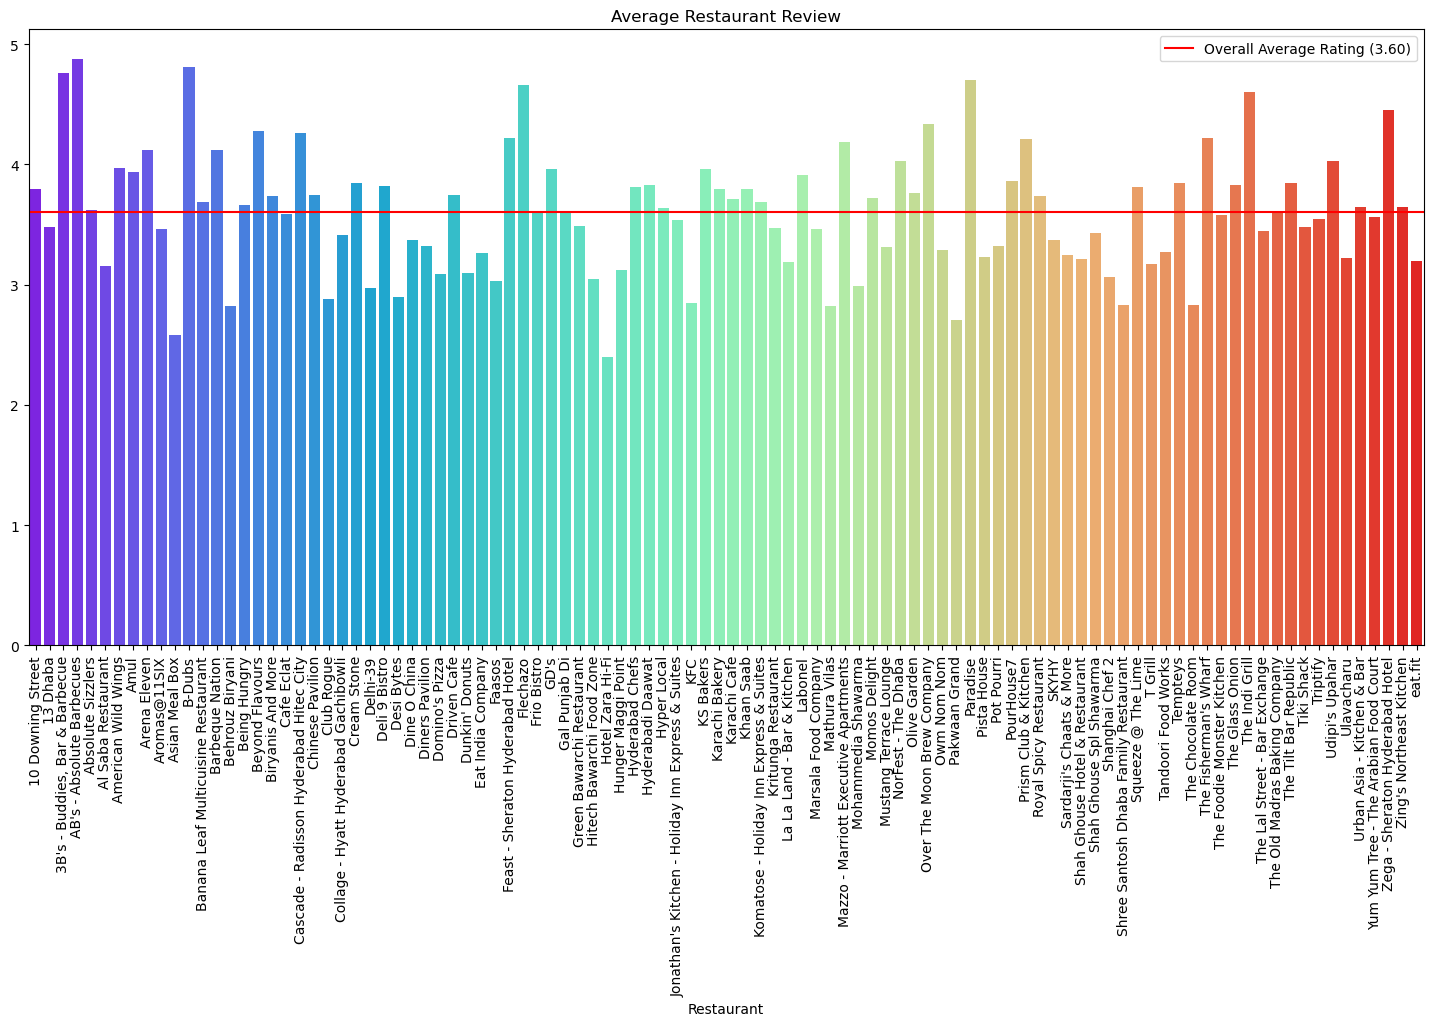

In [7]:
# Average rating for each restaurant - visualization
avg_rating = df.groupby('Restaurant')['Rating'].mean()

plt.figure(figsize=(18,8))
sns.barplot(x=avg_rating.index, y=avg_rating.values, palette='rainbow')
plt.axhline(np.mean(avg_rating.values), color='red', label=f'Overall Average Rating ({np.mean(avg_rating.values):.2f})')
plt.xticks(rotation=90)
plt.legend()
plt.title('Average Restaurant Review')
plt.show()

In [8]:
# Keep only the columns we need, drop rows with missing reviews
data = df[['Restaurant','Reviewer','Review','Rating']].copy()
data = data.dropna(subset=['Review'])
data.head()

,Restaurant,Reviewer,Review,Rating
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5.0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5.0
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5.0
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5.0
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5.0


In [9]:
# Text cleaning function - lowercase, remove special chars, remove stopwords
stop = set(stopwords.words('english'))

def clean_text(txt, stop=stop):
    if not isinstance(txt, str):
        txt = str(txt)
    txt = txt.lower()
    txt = re.sub(r'\\[nt]*', ' ', txt)
    txt = re.sub(r'[^A-Za-z\s]', ' ', txt)
    txt = re.sub(r'[\s+]', ' ', txt)
    txt = " ".join([x for x in txt.split(' ') if x not in stop])
    return txt

data['clean_review'] = data['Review'].apply(clean_text)
data.head()

,Restaurant,Reviewer,Review,Rating,clean_review
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5.0,ambience good food quite good saturday lunc...
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5.0,ambience good pleasant evening service prompt...
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5.0,must try great food great ambience thnx ser...
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5.0,soumen das arun great guy behavior sincerety ...
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5.0,food good ordered kodi drumsticks basket mutto...


In [10]:
# Create binary Target: 0 = Positive (rating > 3), 1 = Negative (rating <= 3)
data['Target'] = data['Rating'].apply(lambda x: 0 if x > 3.0 else 1)
data.head()

,Restaurant,Reviewer,Review,Rating,clean_review,Target
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5.0,ambience good food quite good saturday lunc...,0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5.0,ambience good pleasant evening service prompt...,0
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5.0,must try great food great ambience thnx ser...,0
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5.0,soumen das arun great guy behavior sincerety ...,0
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5.0,food good ordered kodi drumsticks basket mutto...,0


In [11]:
print(data['Target'].value_counts())
print(data['Target'].value_counts(normalize=True) * 100)

Target
0    6315
1    3639
Name: count, dtype: int64
Target
0    63.441832
1    36.558168
Name: proportion, dtype: float64


In [12]:
# Load spacy model for lemmatization
import spacy
nlp = spacy.load('en_core_web_sm')

def lemmatize_review(txt, nlp=nlp):
    words = nlp(txt)
    txt = ' '.join(word.lemma_ for word in words)
    return txt

data['clean_review'] = data['clean_review'].apply(lemmatize_review)
data.head()

,Restaurant,Reviewer,Review,Rating,clean_review,Target
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5.0,ambience good food quite good saturday lu...,0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5.0,ambience good pleasant evening service promp...,0
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5.0,must try great food great ambience thnx s...,0
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5.0,soumen das arun great guy behavior sincerety...,0
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5.0,food good order kodi drumstick basket mutton b...,0


In [13]:
def preprocess_text_for_pred(txt):
    txt = clean_text(txt)
    txt = lemmatize_review(txt, nlp)
    return txt

In [14]:
# Convert to numpy arrays and create TensorFlow dataset
X = data['clean_review'].to_numpy()
Y = data['Target'].to_numpy()

dataset = tf.data.Dataset.from_tensor_slices((X, Y))

split = int(len(data) * 0.8)
train = dataset.take(split)
val = dataset.skip(split)

train = train.batch(64).prefetch(buffer_size=tf.data.AUTOTUNE).cache().shuffle(buffer_size=1000)
val = val.batch(64).prefetch(buffer_size=tf.data.AUTOTUNE).cache().shuffle(buffer_size=1000)

print("Total samples:", len(data))
print("Training samples:", split)
print("Validation samples:", len(data) - split)

Total samples: 9954
Training samples: 7963
Validation samples: 1991


In [15]:
# Build the LSTM model for binary sentiment classification
max_tok = 10000
Vect = tf.keras.layers.TextVectorization(max_tokens=max_tok)
Vect.adapt(dataset.map(lambda x, y: x))

model = tf.keras.models.Sequential([
    Vect,
    tf.keras.layers.Embedding(len(Vect.get_vocabulary()), 128, mask_zero=True),
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(128, return_sequences=True)),
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64, return_sequences=False)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1, activation=None)
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ text_vectorization                   │ ?                           │     0 (unbuilt) │
│ (TextVectorization)                  │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ embedding (Embedding)                │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional (Bidirectional)        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional_1 (Bidirectional)      │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [16]:
# Train the model with early stopping
es_cb = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3)

history = model.fit(train, batch_size=64, validation_data=val, epochs=50, callbacks=[es_cb])

Epoch 1/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 107s 763ms/step - accuracy: 0.7961 - loss: 0.4189 - val_accuracy: 0.8448 - val_loss: 0.3494
Epoch 2/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 104s 825ms/step - accuracy: 0.9037 - loss: 0.2395 - val_accuracy: 0.8553 - val_loss: 0.3452
Epoch 3/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 113s 906ms/step - accuracy: 0.9321 - loss: 0.1784 - val_accuracy: 0.8448 - val_loss: 0.3608
Epoch 4/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 150s 965ms/step - accuracy: 0.9468 - loss: 0.1436 - val_accuracy: 0.8473 - val_loss: 0.4127
Epoch 5/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 148s 1s/step - accuracy: 0.9655 - loss: 0.0963 - val_accuracy: 0.8443 - val_loss: 0.4818


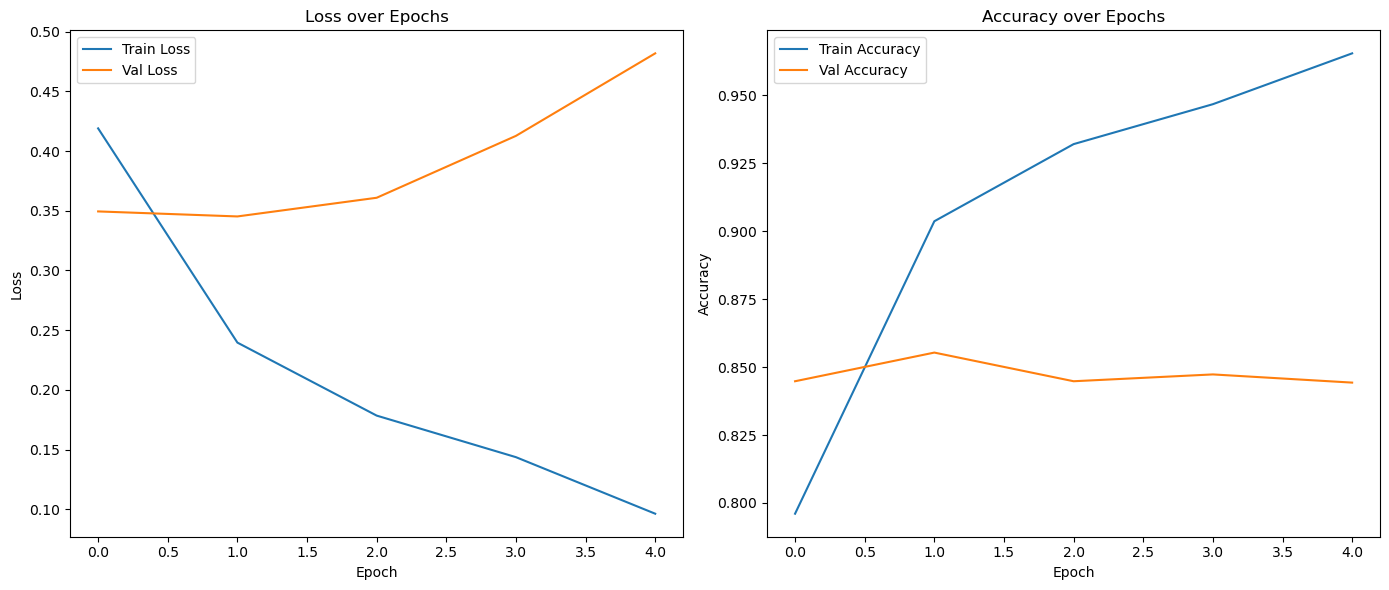

In [17]:
# Plot training curves for the report
def plot_hist(history):
    hist = history.history
    plt.figure(figsize=(14,6))
    
    plt.subplot(1,2,1)
    plt.plot(hist['loss'], label='Train Loss')
    plt.plot(hist['val_loss'], label='Val Loss')
    plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.title('Loss over Epochs')
    
    plt.subplot(1,2,2)
    plt.plot(hist['accuracy'], label='Train Accuracy')
    plt.plot(hist['val_accuracy'], label='Val Accuracy')
    plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.title('Accuracy over Epochs')
    
    plt.tight_layout()
    plt.savefig('lstm_sentiment_training_curves.png', dpi=120)
    plt.show()

plot_hist(history)

32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 223ms/step


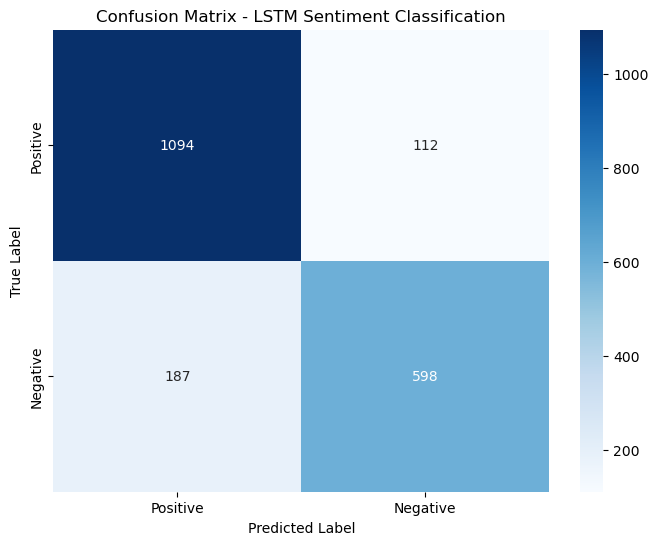


Classification Report:
              precision    recall  f1-score   support

    Positive       0.85      0.91      0.88      1206
    Negative       0.84      0.76      0.80       785

    accuracy                           0.85      1991
   macro avg       0.85      0.83      0.84      1991
weighted avg       0.85      0.85      0.85      1991



In [19]:
# Fix: create a non-shuffled version of validation data for correct evaluation
# (shuffle causes mismatched order when predictions and labels are computed separately)
val_eval = dataset.skip(split).batch(64)

y_pred_logits = model.predict(val_eval.map(lambda x, y: x))
y_pred = (tf.sigmoid(y_pred_logits) > 0.5).numpy().astype(int)

y_true = []
for _, labels in val_eval:
    y_true.extend(labels.numpy())

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Positive', 'Negative'], 
            yticklabels=['Positive', 'Negative'])
plt.title('Confusion Matrix - LSTM Sentiment Classification')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.savefig('lstm_confusion_matrix.png', dpi=120)
plt.show()

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=['Positive', 'Negative']))

In [20]:
# Function to classify a single review
def classify_review(review, model):
    cleaned_review = preprocess_text_for_pred(review)
    review_array = np.array([cleaned_review])
    review_tensor = tf.data.Dataset.from_tensor_slices(review_array).batch(1)
    prediction = model.predict(review_tensor, verbose=0)
    predicted_class = 0 if prediction[0] < 0 else 1
    return "Positive Review" if predicted_class == 0 else "Negative Review"

# Test on new, unseen reviews
sample_reviews = [
    "The food was fantastic and the service was excellent!",
    "The service was terrible and the food was cold.",
    "It was okay, nothing special but not bad either.",
    "Amazing ambience, will definitely come back!",
    "Worst experience ever, would not recommend."
]

print("=== Sample Predictions ===\n")
for review in sample_reviews:
    result = classify_review(review, model)
    print(f"Review: \"{review}\"")
    print(f"Prediction: {result}\n")

=== Sample Predictions ===

Review: "The food was fantastic and the service was excellent!"
Prediction: Positive Review

Review: "The service was terrible and the food was cold."
Prediction: Negative Review

Review: "It was okay, nothing special but not bad either."
Prediction: Negative Review

Review: "Amazing ambience, will definitely come back!"
Prediction: Positive Review

Review: "Worst experience ever, would not recommend."
Prediction: Negative Review



In [21]:
# Save the trained model - this will be loaded later by the Streamlit frontend
model.save('restaurant_sentiment_model.h5')
print("Model saved successfully!")

Model saved successfully!


In [22]:
# Save in the newer, recommended Keras format as well
model.save('restaurant_sentiment_model.keras')
print("Model saved successfully in .keras format!")

Model saved successfully in .keras format!


In [23]:
# Quick test: reload the model and verify it still works
loaded_model = tf.keras.models.load_model('restaurant_sentiment_model.keras')

test_review = "The food was amazing and I loved the ambience!"
result = classify_review(test_review, loaded_model)
print(f"Review: \"{test_review}\"")
print(f"Prediction: {result}")

Review: "The food was amazing and I loved the ambience!"
Prediction: Positive Review
